# P and Q: laws, likelihoods and valuation

Family 16. The physical drift and pricing drift are supplied independently.
Reweighting has meaning only because the two specified GBM laws share diffusion
coefficients. Time is in years; rates and volatilities are decimals.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import contracts as ct, curves as cv, pricing as pr
rng = np.random.default_rng(1600)
ref, expiry = '2026-01-01', '2027-01-01'
discount, dividend = cv.flat_curve(ref, .04), cv.flat_curve(ref, .01)
model = pr.BlackScholesModel(100., discount, dividend, .2)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Change a drift, preserve diffusion

The market price of Brownian risk links these two model specifications.
The same physical Brownian draws support a likelihood-ratio comparison with the
analytic Q expectation. Finite-sample normalization changes the estimator.

,quantity,value
0,P mean,112.761857
1,Q analytic mean,103.045453
2,Q self-normalized mean,102.983208
3,Mean dQ/dP,1.000941
4,Weight effective size,48946.072903


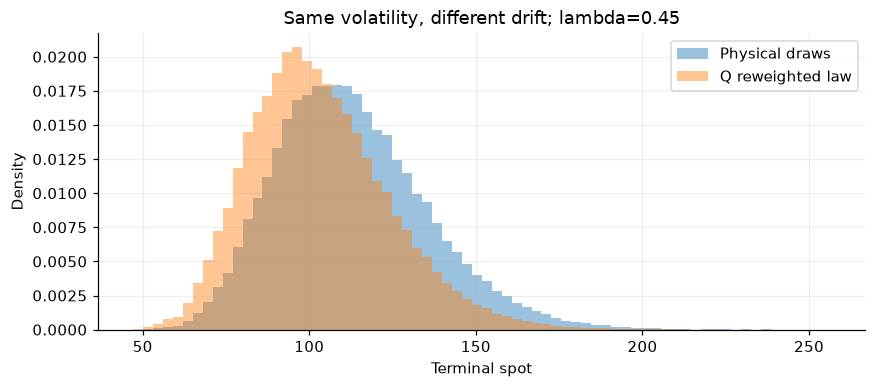

In [2]:
from convexity.math import measures as me, simulation as sim
pair = me.gbm_pair(.12,.04,.01,.2)
lam = pair.market_price_of_risk(0.,100.)[0]
z = rng.normal(size=60000)
terminal = 100*np.exp(.12-.5*.2**2+.2*z)
log_density = me.girsanov_log_density(z[:,None,None], [lam], [1.])
paths = sim.PathScenarios([0.,1.],np.c_[np.full(len(z),100.),terminal],sampling='iid')
q_paths = me.reweight(paths,log_density)
display(pd.DataFrame({'quantity':['P mean','Q analytic mean','Q self-normalized mean','Mean dQ/dP','Weight effective size'],
                     'value':[terminal.mean(),100*np.exp(.03),q_paths.mean()[-1],np.exp(log_density).mean(),q_paths.effective_size]}))
fig,ax=plt.subplots()
ax.hist(terminal,bins=70,density=True,alpha=.45,label='Physical draws')
ax.hist(terminal,bins=70,weights=q_paths.weights,density=True,alpha=.45,label='Q reweighted law')
ax.set(xlabel='Terminal spot',ylabel='Density',title=f'Same volatility, different drift; lambda={lam:.2f}')
ax.legend();plt.show()

## Weight concentration as the drift gap grows

Weight concentration measures the difficulty of importance sampling. It is not
the number of independent observations after reweighting, and it does not justify
an IID standard error.

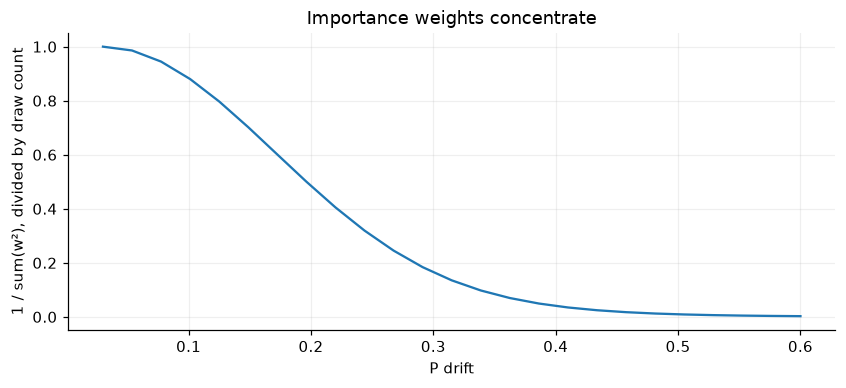

In [3]:
rows=[]
for mu in np.linspace(.03,.6,25):
    risk=(mu-.03)/.2
    weights=me.reweight(paths,me.girsanov_log_density(z[:,None,None],[risk],[1.]))
    rows.append((mu,risk,weights.effective_size/len(z)))
concentration=pd.DataFrame(rows,columns=['P drift','Risk premium','Effective size fraction'])
concentration.plot(x='P drift',y='Effective size fraction',legend=False)
plt.ylabel('1 / sum(w²), divided by draw count');plt.title('Importance weights concentrate');plt.show()

## Discounted Q payoffs and explicit composition

Pricing uses the supplied Q numeraire. The reweighted finite law supplies a
price estimate without an automatic Monte Carlo standard error. The analytic
price is an independent QuantLib reference.

,method,value,standard error
0,QuantLib analytic,9.319738,None
1,Reweighted P scenarios,9.314892,None


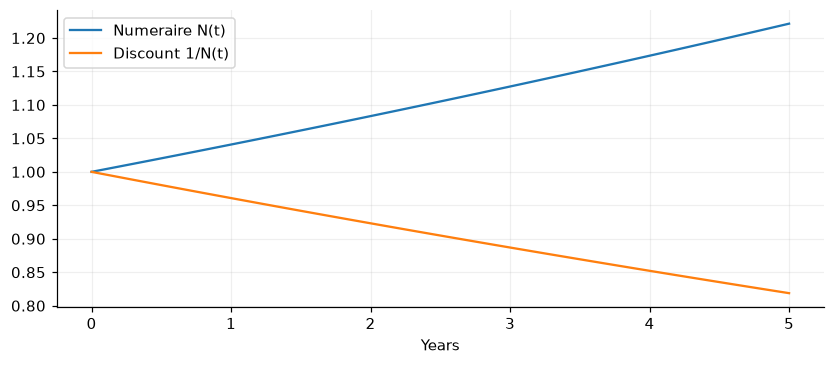

In [4]:
q_model=pr.BlackScholesModel.from_measure_pair(pair,100.,ref)
contract=ct.VanillaContract(100.,ct.Exercise('european',(expiry,)))
analytic=pr.price(pr.PricingProblem(contract,q_model,ref),pr.VanillaEngine())
scenarios=pr.scenario_price(q_paths,lambda path:max(path[-1]-100.,0.),pair.pricing)
display(pd.DataFrame({'method':['QuantLib analytic','Reweighted P scenarios'],
                     'value':[analytic.value,scenarios.value],
                     'standard error':[analytic.error_estimate,scenarios.error_estimate]}))
t=np.linspace(0,5,50)
plt.plot(t,me.MoneyMarketNumeraire(.04).value(t),label='Numeraire N(t)')
plt.plot(t,np.exp(-.04*t),label='Discount 1/N(t)');plt.xlabel('Years');plt.legend();plt.show()

## Scope of the evidence

These are generated-data experiments under the stated models, not market forecasts or universal model rankings. Numerical errors, backend restrictions and measure assumptions are documented in the [financial catalog](../financial_mathematics.md) and [QA record](../financial_qa.md). Automated adversarial checks live in `tests/math/finance/`.